Iteration  1: Best Distance = 37
Iteration  2: Best Distance = 37
Iteration  3: Best Distance = 36
Iteration  4: Best Distance = 36
Iteration  5: Best Distance = 36
Iteration  6: Best Distance = 36
Iteration  7: Best Distance = 36
Iteration  8: Best Distance = 36
Iteration  9: Best Distance = 36
Iteration 10: Best Distance = 36
Iteration 11: Best Distance = 36
Iteration 12: Best Distance = 36
Iteration 13: Best Distance = 36
Iteration 14: Best Distance = 36
Iteration 15: Best Distance = 36
Iteration 16: Best Distance = 36
Iteration 17: Best Distance = 36
Iteration 18: Best Distance = 36
Iteration 19: Best Distance = 36
Iteration 20: Best Distance = 36
Iteration 21: Best Distance = 36
Iteration 22: Best Distance = 36
Iteration 23: Best Distance = 36
Iteration 24: Best Distance = 36
Iteration 25: Best Distance = 36
Iteration 26: Best Distance = 36
Iteration 27: Best Distance = 36
Iteration 28: Best Distance = 36
Iteration 29: Best Distance = 36
Iteration 30: Best Distance = 36
Iteration 

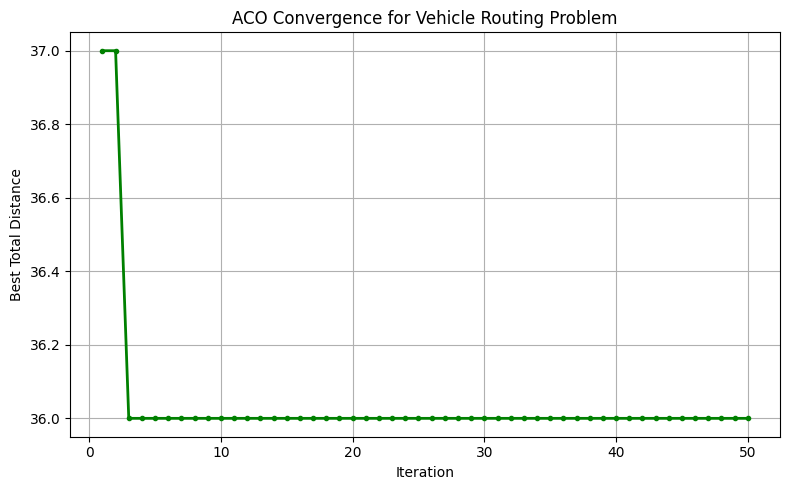

In [1]:

import random
import matplotlib.pyplot as plt

# ============================================================
# ANT COLONY OPTIMIZATION (ACO)
# VEHICLE ROUTING PROBLEM (VRP)
# ============================================================

random.seed(1)

# 1. Distance Matrix (City 0 is the Depot)
d = [
    [0, 2, 9, 10, 7, 3],
    [2, 0, 6, 4, 3, 5],
    [9, 6, 0, 8, 5, 7],
    [10, 4, 8, 0, 6, 4],
    [7, 3, 5, 6, 0, 2],
    [3, 5, 7, 4, 2, 0]
]

# 2. Customer Demands
demand = [0, 2, 3, 4, 2, 3]

# 3. Initialize Parameters
n = len(d)
capacity = 7
vehicles = 3
ants = 10
iterations = 50

alpha = 1
beta = 2
rho = 0.5
Q = 100

# 4. Initialize Pheromone Matrix
pher = [
    [1.0 if i != j else 0 for j in range(n)]
    for i in range(n)
]

# Store best solution
best_routes = None
best_dist = float('inf')

# Store convergence history
history = []


# ============================================================
# 5. MAIN ACO LOOP
# ============================================================

for iteration in range(iterations):

    solutions = []

    # Each ant constructs a solution
    for ant in range(ants):

        unvisited = set(range(1, n))
        routes = []
        total = 0

        # Assign routes to vehicles
        for v in range(vehicles):

            route = [0]
            load = 0

            while True:

                current = route[-1]

                # Find feasible customers
                choices = [
                    j for j in unvisited
                    if demand[j] <= capacity - load
                ]

                if not choices:
                    break

                # Calculate selection probabilities
                weights = [
                    (pher[current][j] ** alpha) *
                    ((1 / d[current][j]) ** beta)
                    for j in choices
                ]

                # Roulette wheel selection
                r = random.random() * sum(weights)
                cumulative = 0

                for j, w in zip(choices, weights):

                    cumulative += w

                    if cumulative >= r:
                        route.append(j)
                        load += demand[j]
                        unvisited.remove(j)
                        break

            # Return vehicle to depot
            if len(route) > 1:

                route.append(0)

                distance = sum(
                    d[route[k]][route[k + 1]]
                    for k in range(len(route) - 1)
                )

                total += distance
                routes.append(route)

            if not unvisited:
                break

        # Accept only complete solutions
        if not unvisited:

            solutions.append((routes, total))

            # Update global best
            if total < best_dist:

                best_dist = total
                best_routes = [r[:] for r in routes]

    # ========================================================
    # 6. PHEROMONE EVAPORATION
    # ========================================================

    for i in range(n):
        for j in range(n):

            if i != j:
                pher[i][j] *= (1 - rho)

    # ========================================================
    # 7. PHEROMONE DEPOSIT
    # ========================================================

    for routes, length in solutions:

        for route in routes:

            for k in range(len(route) - 1):

                a = route[k]
                b = route[k + 1]

                pher[a][b] += Q / length
                pher[b][a] += Q / length

    # Store best distance
    history.append(best_dist)

    print(
        f"Iteration {iteration + 1:2d}: "
        f"Best Distance = {best_dist}"
    )


# ============================================================
# 8. DISPLAY FINAL RESULTS
# ============================================================

print("\n====================================")
print("ANT COLONY OPTIMIZATION - VRP")
print("====================================")

print("\nBest Vehicle Routes:")

for i, route in enumerate(best_routes, 1):

    print(
        "Vehicle", i, ":",
        " -> ".join(map(str, route))
    )

print("\nMinimum Total Distance:", best_dist)


# ============================================================
# 9. DISPLAY VEHICLE LOADS
# ============================================================

print("\nVehicle Loads:")

for i, route in enumerate(best_routes, 1):

    load = sum(demand[city] for city in route)

    print(
        f"Vehicle {i}: Load = {load}/{capacity}"
    )


# ============================================================
# 10. CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, iterations + 1),
    history,
    color='green',
    linewidth=2,
    marker='o',
    markersize=3
)

plt.title("ACO Convergence for Vehicle Routing Problem")
plt.xlabel("Iteration")
plt.ylabel("Best Total Distance")

plt.grid(True)
plt.tight_layout()
plt.show()
